In [61]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from LD.utils.ld_tools import *
from sklearn.cluster import KMeans
import umap
from sklearn.manifold import trustworthiness
from LD.utils.ld_tools import *
from sklearn import datasets
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.preprocessing import StandardScaler


In [62]:
alpha2 = 15
dim_reduction = 2

# # --- IRIS --- #
# points0 = datasets.load_iris().data

# # --- MNIST --- #
# (x_train, _), (x_test, _) = mnist.load_data()
# # images = np.concatenate((x_train, x_test), axis=0)
# images = x_test
# points0 = images.reshape(images.shape[0], -1)
# points0 = points0 / 255.0

# --- MNIST --- #
(x_train, _), (x_test, y_test) = mnist.load_data()
points_all = x_test.reshape(x_test.shape[0], -1) / 255.0
indices = np.concatenate([np.where(y_test == i)[0][:200] for i in range(10)])
points0 = points_all[indices]

# # --- DIGITS --- #
# points0, _ = datasets.load_digits(return_X_y=True)

# # --- SWISS ROLL --- #
# points0, _ = datasets.make_swiss_roll(n_samples=5000, noise=0.1)

In [63]:
scaler = StandardScaler()
points = scaler.fit_transform(points0)

## Avec Fermat

In [64]:
dist_mat = distance_matrix(points, points)
fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
umap_reducer_fermat = umap.UMAP(n_components=dim_reduction, metric='precomputed')
umap_reducer_fermat.fit(fermat_dist_mat)


c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


,n_neighbors,15
,n_components,2
,metric,'precomputed'
,metric_kwds,None
,output_metric,'euclidean'
,output_metric_kwds,None
,n_epochs,None
,learning_rate,1.0
,init,'spectral'
,min_dist,0.1
,spread,1.0


In [65]:
points_reduced_fermat = umap_reducer_fermat.embedding_
dist_mat_umap = distance_matrix(points_reduced_fermat, points_reduced_fermat)
fermat_umap = fermat_function(dist_mat_umap, alpha=alpha2)

### Comparaison avec fermat

In [66]:
score_ff = trustworthiness(X= fermat_dist_mat, X_embedded= fermat_umap, n_neighbors=20, metric='precomputed')
print(f"Trustworthiness score fermat / fermat: {score_ff:.4f}")

Trustworthiness score fermat / fermat: 0.6707


### Comparaison avec euclidienne

In [67]:
score_fe = trustworthiness(X= dist_mat, X_embedded= dist_mat_umap, n_neighbors=20, metric='precomputed')
print(f"Trustworthiness score fermat / euclidienne: {score_fe:.4f}")

Trustworthiness score fermat / euclidienne: 0.7797


## Avec Euclidienne

In [68]:
dist_mat = distance_matrix(points, points)
umap_reducer_fermat = umap.UMAP(n_components=dim_reduction, metric='precomputed')
umap_reducer_fermat.fit(dist_mat)


c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


,n_neighbors,15
,n_components,2
,metric,'precomputed'
,metric_kwds,None
,output_metric,'euclidean'
,output_metric_kwds,None
,n_epochs,None
,learning_rate,1.0
,init,'spectral'
,min_dist,0.1
,spread,1.0


In [69]:
points_reduced_eucl = umap_reducer_fermat.embedding_
dist_mat_umap = distance_matrix(points_reduced_eucl, points_reduced_eucl)
fermat_umap = fermat_function(dist_mat_umap, alpha=alpha2)

### Comparaison avec fermat

In [70]:
score_ef = trustworthiness(X= dist_mat, X_embedded= fermat_umap, n_neighbors=20, metric='precomputed')
print(f"Trustworthiness score euclidienne / fermat: {score_ef:.4f}")

Trustworthiness score euclidienne / fermat: 0.7759


### Comparaison avec euclidienne

In [71]:
score_ee = trustworthiness(X= dist_mat, X_embedded= dist_mat_umap, n_neighbors=20, metric='precomputed')
print(f"Trustworthiness score euclidienne / euclidienne: {score_ee:.4f}")

Trustworthiness score euclidienne / euclidienne: 0.8530


## Recapitulatif

In [72]:
print(f"========== Resultats tests trustworthiness ==========\n")
print("                      reduction umap avec: |           Fermat           |     Euclidienne           |")
print("trustoworthiness avec:                     |----------------------------|---------------------------|")
print("                    Fermat                 |           {:.4f}           |           {:.4f}          |".format(score_ff, score_fe))
print("                  Euclidienne              |           {:.4f}           |           {:.4f}          |".format(score_ef, score_ee))

========== Resultats tests trustworthiness ==========

                      reduction umap avec: |           Fermat           |     Euclidienne           |
trustoworthiness avec:                     |----------------------------|---------------------------|
                    Fermat                 |           0.6707           |           0.7797          |
                  Euclidienne              |           0.7759           |           0.8530          |


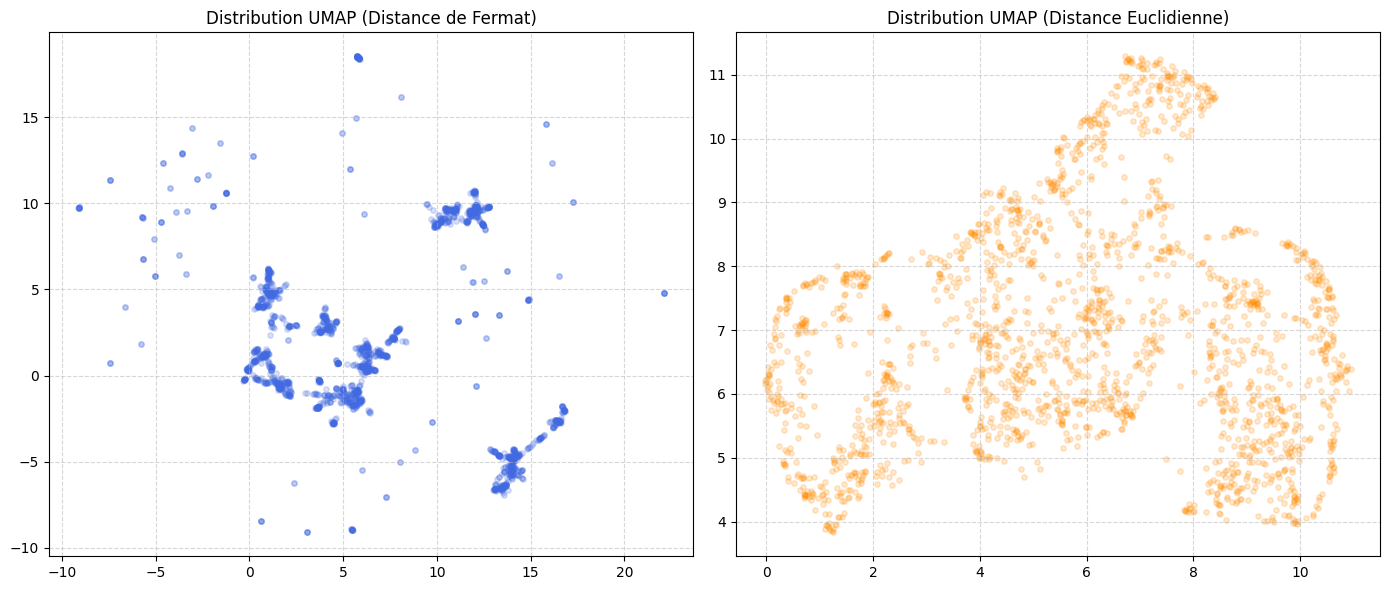

In [77]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(points_reduced_fermat[:, 0], points_reduced_fermat[:, 1], 
            color='royalblue', s=15, alpha=0.2)
ax1.set_title("Distribution UMAP (Distance de Fermat)")
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.scatter(points_reduced_eucl[:, 0], points_reduced_eucl[:, 1], 
            color='darkorange', s=15, alpha=0.2)
ax2.set_title("Distribution UMAP (Distance Euclidienne)")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

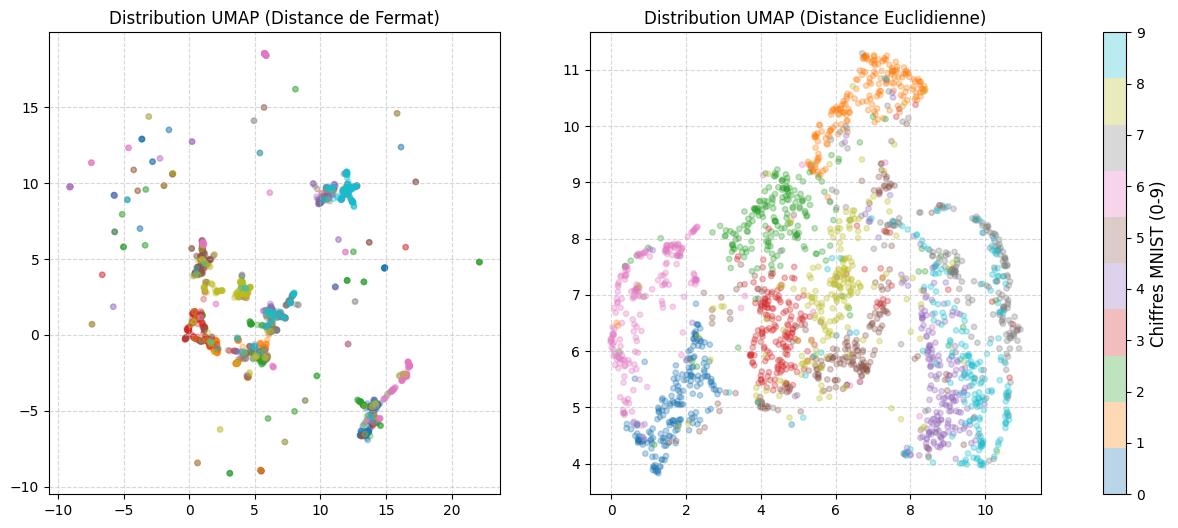

In [79]:
labels = y_test[indices]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

scatter1 = ax1.scatter(points_reduced_fermat[:, 0], points_reduced_fermat[:, 1], 
                      c=labels, cmap='tab10', s=15, alpha=0.3)
ax1.set_title("Distribution UMAP (Distance de Fermat)")
ax1.grid(True, linestyle='--', alpha=0.5)

scatter2 = ax2.scatter(points_reduced_eucl[:, 0], points_reduced_eucl[:, 1], 
                      c=labels, cmap='tab10', s=15, alpha=0.3)
ax2.set_title("Distribution UMAP (Distance Euclidienne)")
ax2.grid(True, linestyle='--', alpha=0.5)

cbar = fig.colorbar(scatter2, ax=[ax1, ax2], pad=0.05, ticks=range(10))
cbar.set_label('Chiffres MNIST (0-9)', fontsize=12)

plt.show()